# January 2026 UK wind forecast error analysis

Data: Elexon BMRS snapshot in `api/data/` (built by `scripts/fetch_data.py`).
- **Actuals**: FUELHH `WIND`, 30-min. These are averaged to hourly to match the forecasts.
- **Forecasts**: WINDFOR, hourly, 8 publishes per day.

**Error = actual − forecast.** A negative error means wind under-delivered, so the shortfall must be bought.

The question for the day-ahead desk is how far they can trust the forecast they hold at gate closure (11:00 D-1), and how much wind they can reliably count on.

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": .3})
a = pd.DataFrame(json.load(open("../api/data/actuals.json")))
f = pd.DataFrame(json.load(open("../api/data/forecasts.json")))
a["t"] = pd.to_datetime(a.t); f["t"] = pd.to_datetime(f.t); f["p"] = pd.to_datetime(f.p)
hourly = a.groupby(a.t.dt.floor("h")).mw.agg(["mean", "size"]).query("size == 2")["mean"].rename("actual")
print(len(a), "half-hours ->", len(hourly), "hours;", f.p.nunique(), "forecast publishes")

1488 half-hours -> 744 hours; 272 forecast publishes


## 1. Forecast available at the day-ahead gate
For each target hour on delivery day D, take the latest publish at or before 11:00 on D-1. In January, UK time is UTC.

In [2]:
def select(cutoff_fn):
    df = f.copy()
    df["cutoff"] = cutoff_fn(df.t)
    df = df[df.p <= df.cutoff].sort_values("p").groupby("t").tail(1).set_index("t")
    out = df.join(hourly, how="inner")
    out["error"] = out.actual - out.mw
    out["lead_h"] = (out.index - out.p).dt.total_seconds() / 3600
    return out.rename(columns={"mw": "forecast"})

gate = select(lambda t: t.dt.normalize() - pd.Timedelta(days=1) + pd.Timedelta(hours=11))
gate = gate[gate.index >= "2026-01-01"]
print(gate.p.dt.strftime("%H:%M").value_counts().to_dict(), "| lead time range", gate.lead_h.min(), "-", gate.lead_h.max(), "h")
e = gate.error
pd.Series({"n": len(e), "MAE": e.abs().mean(), "RMSE": (e**2).mean()**.5, "bias": e.mean(),
           "P10": e.quantile(.1), "P50": e.median(), "P90": e.quantile(.9),
           "nMAE % of mean actual": 100 * e.abs().mean() / gate.actual.mean()}).round(1)

{'09:30': 744} | lead time range 14.5 - 37.5 h


n                         744.0
MAE                      2122.8
RMSE                     2616.7
bias                    -1840.3
P10                     -4312.4
P50                     -1640.5
P90                       488.9
nMAE % of mean actual      18.3
dtype: float64

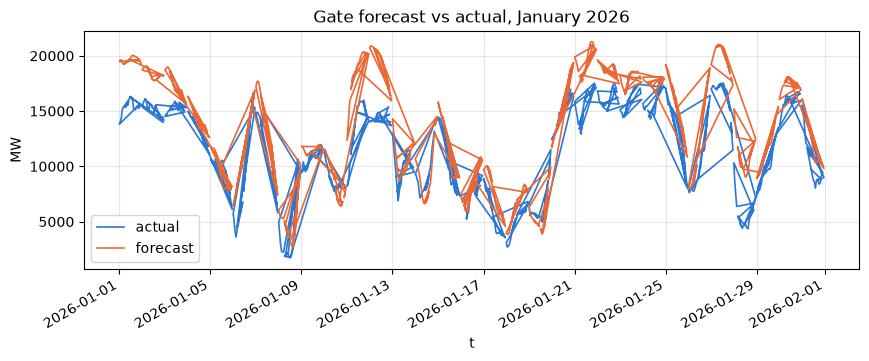

In [3]:
ax = gate[["actual", "forecast"]].plot(color=["#2a78d6", "#eb6834"], lw=1.2)
ax.set_ylabel("MW"); ax.set_title("Gate forecast vs actual, January 2026");

## 2. How does error grow with lead time?
Horizon mode: for each hour, take the latest publish at least H hours earlier.

h,0,2,4,6,8,10,12,14,16,18,...,30,32,34,36,38,40,42,44,46,48
n,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,...,744.0,744.0,744.0,744.0,744.0,744.0,744.0,713.0,651.0,589.0
MAE,1800.0,1820.0,1846.0,1881.0,1897.0,1896.0,1907.0,1932.0,1964.0,1990.0,...,2204.0,2238.0,2252.0,2270.0,2292.0,2308.0,2320.0,2361.0,2395.0,2387.0
RMSE,2287.0,2318.0,2339.0,2357.0,2368.0,2372.0,2384.0,2407.0,2434.0,2459.0,...,2655.0,2696.0,2727.0,2758.0,2791.0,2819.0,2847.0,2891.0,2931.0,2939.0
bias,-1593.0,-1609.0,-1645.0,-1684.0,-1695.0,-1691.0,-1704.0,-1731.0,-1762.0,-1791.0,...,-1898.0,-1916.0,-1935.0,-1951.0,-1961.0,-1954.0,-1940.0,-1943.0,-1932.0,-1868.0


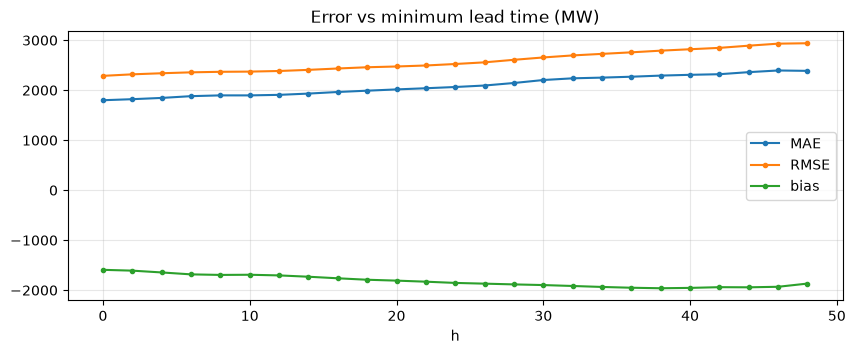

In [4]:
rows = []
for h in range(0, 49, 2):
    s = select(lambda t: t - pd.Timedelta(hours=h)); s = s[s.index >= "2026-01-01"]
    rows.append({"h": h, "n": len(s), "MAE": s.error.abs().mean(), "RMSE": (s.error**2).mean()**.5, "bias": s.error.mean()})
curve = pd.DataFrame(rows).set_index("h")
curve[["MAE", "RMSE", "bias"]].plot(marker=".", title="Error vs minimum lead time (MW)"); curve.round(0).T

Error grows slowly with lead time, from about 1.8 GW MAE at 0h to about 2.4 GW at 48h. Above 44h the sample shrinks, because each WINDFOR publish only reaches D+2 21:00. But even the freshest forecast has large error, and almost all of it is **bias**. So the dominant problem is not weather uncertainty: something systematic separates WINDFOR from FUELHH.

## 3. Where does the bias come from?

,count,mean,std,min,10%,50%,90%,max
forecast,,,,,,,,
"(2000, 4000]",13.0,0.86,0.38,0.50,0.53,0.71,1.39,1.65
"(4000, 6000]",43.0,0.90,0.34,0.37,0.43,0.80,1.26,1.81
"(6000, 8000]",65.0,0.99,0.21,0.48,0.74,1.01,1.23,1.47
"(8000, 10000]",98.0,0.87,0.20,0.44,0.54,0.87,1.14,1.28
"(10000, 12000]",107.0,0.86,0.13,0.47,0.74,0.88,1.01,1.12
"(12000, 14000]",64.0,0.88,0.13,0.50,0.70,0.90,1.01,1.06
"(14000, 16000]",62.0,0.92,0.11,0.60,0.81,0.94,1.03,1.10
"(16000, 18000]",106.0,0.88,0.07,0.65,0.82,0.88,0.96,1.02
"(18000, 20000]",141.0,0.83,0.06,0.67,0.76,0.83,0.92,0.98


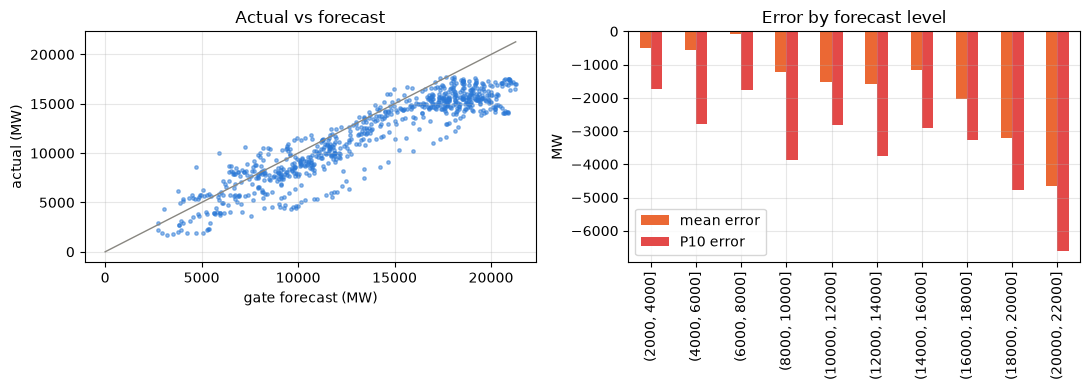

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(gate.forecast, gate.actual, s=6, alpha=.5, color="#2a78d6")
m = max(gate.forecast.max(), gate.actual.max()); ax1.plot([0, m], [0, m], color="#898781", lw=1)
ax1.set(xlabel="gate forecast (MW)", ylabel="actual (MW)", title="Actual vs forecast")
bins = pd.cut(gate.forecast, range(0, 24000, 2000))
gate.groupby(bins, observed=True).error.agg(["mean", lambda x: x.quantile(.1)]).plot.bar(ax=ax2, color=["#eb6834", "#e34948"])
ax2.legend(["mean error", "P10 error"]); ax2.set(title="Error by forecast level", ylabel="MW", xlabel="")
plt.tight_layout()
gate.assign(ratio=gate.actual / gate.forecast).groupby(bins, observed=True).ratio.describe(percentiles=[.1, .5, .9]).round(2)

**Observation.** The shortfall grows with the forecast level. The median ratio of actual to forecast is about 0.9–1.0 below 16 GW, but falls to about 0.8 above 18 GW. Actual output seldom goes past about 17–18 GW, even when the forecast says 20+ GW. Below about 8 GW the ratio is noisy in both directions (pure weather error).

**Likely causes (hypotheses, not verified with this data alone):**
1. **Curtailment / constraints.** FUELHH is metered output after balancing actions. In windy periods, Scottish wind is routinely turned down for transmission constraints, which caps delivered output below what the weather allows.
2. **Scope mismatch.** The units covered by WINDFOR and FUELHH `WIND` may not be identical (for example, embedded vs transmission-connected capacity).

Either way, the effect is systematic, so it can be corrected. It should not be treated as random noise.

## 4. Error patterns by time of day and by day

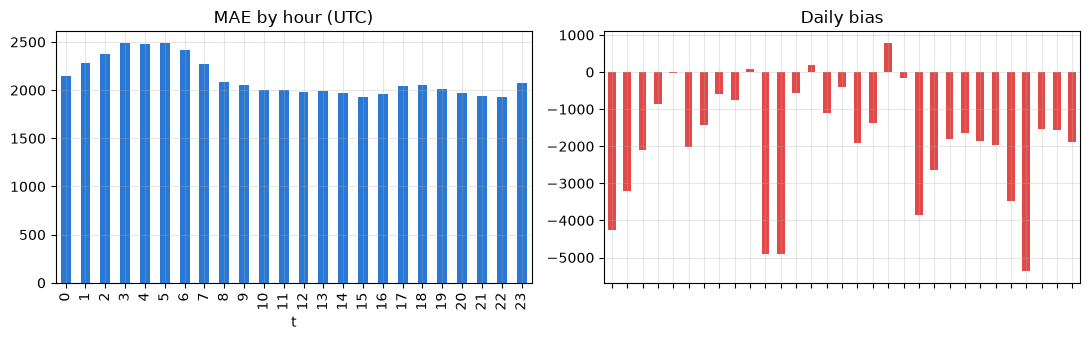

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
gate.groupby(gate.index.hour).error.apply(lambda x: x.abs().mean()).plot.bar(ax=ax1, color="#2a78d6", title="MAE by hour (UTC)")
gate.groupby(gate.index.date).error.mean().plot.bar(ax=ax2, color="#e34948", title="Daily bias"); ax2.set_xticklabels([])
plt.tight_layout()

## 5. How much wind can the desk rely on?

In [7]:
ratio = (gate.actual / gate.forecast)
k10 = ratio.quantile(.1)
print(f"Additive buffer:  in 90% of hours, actual >= forecast {e.quantile(.1):+.0f} MW")
print(f"Ratio buffer:     in 90% of hours, actual >= {k10:.2f} x forecast")
print(f"Unconditional:    wind exceeded {hourly['2026-01'].quantile(.1):.0f} MW in 90% of January hours (P10 of actual)")
cov = lambda lo: (gate.actual >= lo).mean()
print(f"Coverage check: additive {cov(gate.forecast + e.quantile(.1)):.0%}, ratio {cov(gate.forecast * k10):.0%}")

Additive buffer:  in 90% of hours, actual >= forecast -4312 MW
Ratio buffer:     in 90% of hours, actual >= 0.70 x forecast
Unconditional:    wind exceeded 5620 MW in 90% of January hours (P10 of actual)
Coverage check: additive 90%, ratio 90%


### Recommendation
- **Don't take the raw WINDFOR number at face value.** In January 2026, the gate forecast over-forecast delivered wind by about **1.8 GW on average** (MAE about 2.1 GW, about 18% of mean output).
- **Plan procurement against a conservative wind figure.** In January, 90% of hours delivered **at least 0.70 × the gate forecast**, or equivalently at least the forecast minus 4.3 GW. The ratio rule is the better fit because the shortfall scales with the forecast level. The P10 band in the web app shows the additive version.
- **Use the latest pre-gate publish (09:30 D-1).** Each extra hour of lead time adds only a modest amount of error, so the gain from a fresher forecast is real but small compared with the bias.

**Caveats.** This is one winter month, and every quantile here is in-sample. Before relying on these buffers, validate them on more months with a rolling, out-of-sample window.